# Decision Tree
- Data splitting
- Adjusting values
- Training model
- Noise Checking

In [1]:
IMPORT_MODEL = False
PARAMETERS_ADJUSTMENT = False
model_name = "11_tree"

max_depth = 11
msl = 30

In [2]:
import pandas as pd
import numpy as np

import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split

from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score

from sklearn.tree import DecisionTreeClassifier

%matplotlib inline

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from EDA_and_modeling.functional_files import _featuring, _data, _model_impex, _evaluating
import importlib
importlib.reload(_data)
importlib.reload(_featuring)
importlib.reload(_evaluating)
importlib.reload(_model_impex)

print('Libraries loaded!')

pd.set_option('display.max_rows', None)      # all rows
pd.set_option('display.max_columns', None)   # all columns
pd.set_option('display.width', None)         # no line wrapping
pd.set_option('display.max_colwidth', None)  # don't truncate cell contents

Featuring File: Libraries loaded!
Data File: Libraries loaded!
Model Impex File: Libraries loaded!
Evaluating File: Libraries loaded!
Data File: Libraries loaded!
Featuring File: Libraries loaded!
Evaluating File: Libraries loaded!
Model Impex File: Libraries loaded!
Libraries loaded!


## Data

In [3]:
df, _ = _data.get_data('1')

In [4]:
x = df.drop(columns='is_fraud')
y = df['is_fraud']
x_temp_raw, x_test_raw, y_temp, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)
x_train_raw, x_val_raw, y_train, y_val = train_test_split(x_temp_raw, y_temp, test_size=0.25, stratify=y_temp,
                                                          random_state=42)
x_train_raw = _featuring.simple(x_train_raw)
x_val_raw = _featuring.simple(x_val_raw)
x_test_raw = _featuring.simple(x_test_raw)

## Model

In [5]:
if IMPORT_MODEL:
    dv, _ = _model_impex.import_model(model_name)
    x_train = _model_impex.dv_transform(dv, x_train_raw)
    x_val = _model_impex.dv_transform(dv, x_val_raw)
    x_test = _model_impex.dv_transform(dv, x_test_raw)
else:
    dv = _model_impex.dv_initializing(x_train_raw)
    x_train = _model_impex.dv_transform(dv, x_train_raw)
    x_val = _model_impex.dv_transform(dv, x_val_raw)
    x_test = _model_impex.dv_transform(dv, x_test_raw)

### First stage of parameter adjustment

In [6]:
# msl_options = list(np.arange(1, 200, 10))
# roc_auc_history = []
# pr_auc_history = []
#
# for msl in msl_options:
#     current_model = DecisionTreeClassifier(max_depth=8, min_samples_leaf=msl)
#     current_model.fit(x_train, y_train)
#     current_prediction = current_model.predict_proba(x_val)[:, 1]
#     current_roc_auc = roc_auc_score(y_val, current_prediction)
#     current_pr_auc = average_precision_score(y_val, current_prediction)
#     roc_auc_history += [current_roc_auc]
#     pr_auc_history += [current_pr_auc]
#     print(f"MSL: {msl}\nROC AUC:{round(current_roc_auc, 3)}\nPR AUC: {round(current_pr_auc, 3)}\n")
#
# def plot_dual_line(dataframe, x, y1, y2, label1, label2):
#     fig, ax = plt.subplots(figsize=(12, 6))
#
#     lineplot = sns.lineplot(data=dataframe, x=x, y=y1, legend=False, label=label1)
#
#     sns.despine()
#     plt.title("Title")
#
#     ax2 = ax.twinx()
#     lineplot2 = sns.lineplot(data=dataframe, x=x, y=y2, color='r', ax=ax2, legend=False, label=label2)
#     sns.despine(right=False)
#
#     ax.figure.legend()
#     plt.show()
#
# df_score = pd.DataFrame({
#     "depth": msl_options,
#     "roc": roc_auc_history,
#     "pr": pr_auc_history,
# })
# plot_dual_line(df_score, 'depth', 'roc', 'pr', 'ROC', 'PR')

In [7]:
if PARAMETERS_ADJUSTMENT:
    scores = []

    for depth in np.arange(1, 20, 2):
        for msl in np.arange(1, 50, 5):
            current_model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=msl)
            current_model.fit(x_train, y_train)
            current_prediction = current_model.predict_proba(x_val)[:, 1]
            current_roc_auc = roc_auc_score(y_val, current_prediction)
            current_pr_auc = average_precision_score(y_val, current_prediction)
            scores.append((depth, msl, current_roc_auc, current_pr_auc))
        print("Depth:", depth)

    df_scores = pd.DataFrame(scores, columns = ['depth', 'msl', 'roc', 'pr'])

In [8]:
if PARAMETERS_ADJUSTMENT:
    df_scores_pivot = df_scores.pivot(index='msl', columns='depth', values='roc')
    sns.heatmap(df_scores_pivot, annot=False)

In [9]:
if PARAMETERS_ADJUSTMENT:
    df_scores_pivot = df_scores.pivot(index='msl', columns='depth', values='pr')
    sns.heatmap(df_scores_pivot, annot=False)

In [10]:
if PARAMETERS_ADJUSTMENT:
    display(df_scores.sort_values(by='roc', ascending=False).head(10))

In [11]:
if PARAMETERS_ADJUSTMENT:
    display(df_scores.sort_values(by='pr', ascending=False).head(10))

In [12]:
if IMPORT_MODEL:
    _, model = _model_impex.import_model(model_name)
else:
    model = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=msl)
    model.fit(x_train, y_train)
    _model_impex.export_model(model_name, dv, model)

In [13]:
predicted = model.predict_proba(x_val)[:, 1]

In [14]:
_evaluating.full_score(y_val, predicted)

ROC AUC: 0.8995669371650667
PR AUC: 0.3658078719429187


{'roc-auc': 0.8995669371650667, 'pr-auc': 0.3658078719429187}

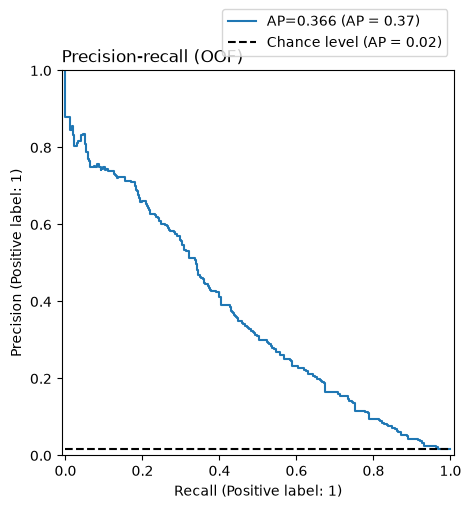

In [15]:
_evaluating.plot_pr_auc(y_val, predicted)

In [16]:
_evaluating.noise_check(y_val, predicted)

[0.34399654 0.38639202]


#### Conclusion 4
Decision Tree model performed much better. It significantly increased ROC-AUC and PR-AUC scores.

In [17]:
_, df_test_raw = _data.get_data('1')
df_test = _model_impex.dv_transform(dv, df_test_raw)
predicted = model.predict_proba(df_test)[:, 1]
_data.kaggle_solution_import(predicted, '11')